# 07 · The gross code, from scratch

**What this notebook is for:** understanding the [[144, 12, 12]] gross code by building it
yourself with numpy, step by step, and checking every claim by computing it.

Path: toric code on a 12 × 6 torus → add two long-range edges per check → gross code;
then the polynomial view, logical qubits, the Tanner graph, logical operators, automorphisms,
and how it compares with the surface code.

**Sources**
| Topic | Source |
|---|---|
| The code, layout, Tanner graph, distance | Bravyi et al., *High-threshold and low-overhead fault-tolerant quantum memory*, Nature 627, 778 (2024), [arXiv:2308.07915](https://arxiv.org/abs/2308.07915) |
| Toric → gross teaching approach, qubit labelling, counting logical qubits | QGSS 2025 Lab 4, Chapter 3 ([qiskit-community/qgss-2025, lab-4/lab4.ipynb](https://github.com/qiskit-community/qgss-2025/tree/main/lab-4)) and Patrick Rall's lecture notes ([QGSS 2025 lecture notes, Day 9](https://github.com/qiskit-community/qgss-2025-lecture-notes)) |
| Instruction set, automorphisms in use | Yoder et al., *Tour de gross*, [arXiv:2506.03094](https://arxiv.org/abs/2506.03094) |
| Code catalogue entry | [Error Correction Zoo: bivariate bicycle codes](https://errorcorrectionzoo.org/c/qcga) |
| Implementations we compare with | stabilizer-qec 2.1.0; Deltakit 0.10.2 (`BivariateBicycleCode`) |

**Figures to look at alongside** (open the paper PDFs; we can't embed them):
- Bravyi et al. Fig. 1: Tanner graph of a distance-3 surface code next to the [[144,12,12]] code drawn on a torus (the long-range edges).
- Bravyi et al. Fig. 2: logical vs physical error rate; the gross code against surface codes holding 12 logical qubits.
- Bravyi et al. Methods: the depth-8 syndrome measurement cycle (the circuit IBM's files implement).
- QGSS 2025 Lab 4 §3.1–3.4 figures: the toric layout with blue/orange data and red/green checks, and the same layout with the two long-range edges per check.
- Tour de gross: the module layout and Table 2 (instruction error rates).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(linewidth=160)

## 1. Shifts on a torus

Put points on an l × m grid that wraps around (a torus). Number point (i, j) as i·m + j.
- `x` shifts every point one step in the first direction: (i, j) → (i+1 mod l, j).
- `y` shifts one step in the second direction: (i, j) → (i, j+1 mod m).

As matrices: x = S_l ⊗ I_m and y = I_l ⊗ S_m, where S_n is the n × n cyclic shift.
x^l = 1 and y^m = 1 (the wrap rule), and xy = yx.

In [2]:
l, m = 12, 6                                     # the gross code's torus
def S(n):
    # n x n cyclic shift matrix: S[i, i+1 mod n] = 1
    return np.roll(np.eye(n, dtype=int), 1, axis=1)
x = np.kron(S(l), np.eye(m, dtype=int))          # shift along the 12 direction
y = np.kron(np.eye(l, dtype=int), S(m))          # shift along the 6 direction
mpow = lambda M, k: np.linalg.matrix_power(M, k) % 2
print("x^12 = 1:", np.array_equal(mpow(x, 12), np.eye(72)), "| y^6 = 1:", np.array_equal(mpow(y, 6), np.eye(72)))
print("xy = yx:", np.array_equal(x @ y % 2, y @ x % 2))

x^12 = 1: True | y^6 = 1: True
xy = yx: True


## 2. Two codes from two pairs of polynomials

A bivariate bicycle code is fixed by two polynomials A and B in x and y. Its checks are

  H_X = [A | B],   H_Z = [Bᵀ | Aᵀ]

with 72 "left" (L) data qubits on the first 72 columns and 72 "right" (R) on the last 72.

- **Toric code** on the same torus: A = 1 + x, B = 1 + y (each check touches 4 neighbours).
- **Gross code**: A = x³ + y + y², B = y³ + x + x² (each check touches 6 qubits: the toric-like
  neighbours plus long-range ones). This is QGSS Lab 4's "toric + two long-range edges" picture
  written as polynomials.

In [3]:
I = np.eye(72, dtype=int)
def bb_code(A, B):
    # check matrices of a bivariate bicycle code from its two polynomial matrices
    HX = np.hstack([A, B]) % 2
    HZ = np.hstack([B.T, A.T]) % 2
    return HX, HZ
HX_t, HZ_t = bb_code(I + x, I + y)                                         # toric
A = (mpow(x, 3) + y + mpow(y, 2)) % 2
B = (mpow(y, 3) + x + mpow(x, 2)) % 2
HX, HZ = bb_code(A, B)                                                     # gross
for name, hx, hz in [("toric", HX_t, HZ_t), ("gross", HX, HZ)]:
    print(f"{name}: H_X {hx.shape}, check weight {set(hx.sum(1).tolist())}, each qubit in {set(hx.sum(0).tolist())} X checks")

toric: H_X (72, 144), check weight {4}, each qubit in {2} X checks
gross: H_X (72, 144), check weight {6}, each qubit in {3} X checks


## 3. Why X and Z checks commute

H_X H_Zᵀ = A B + B A. Because x and y commute, any two polynomials in them commute, so
AB = BA and the sum is 0 mod 2. That one fact is why *any* pair (A, B) gives a valid CSS code.

In [4]:
for name, hx, hz in [("toric", HX_t, HZ_t), ("gross", HX, HZ)]:
    print(name, "H_X H_Z^T = 0 mod 2:", not (hx @ hz.T % 2).any())

toric H_X H_Z^T = 0 mod 2: True
gross H_X H_Z^T = 0 mod 2: True


## 4. Counting logical qubits

k = n − rank(H_X) − rank(H_Z), with ranks over GF(2) (arithmetic mod 2). QGSS Lab 4 §3.5 does
the same count. 72 checks of each type but the rank is less than 72: some checks are products of
others, and that redundancy is where the logical qubits come from.

In [5]:
def gf2_rank(M):
    # rank over GF(2) by Gaussian elimination
    M = M.copy() % 2
    rank, rows, cols = 0, *M.shape
    for c in range(cols):
        piv = np.nonzero(M[rank:, c])[0]
        if len(piv) == 0:
            continue
        p = rank + piv[0]
        M[[rank, p]] = M[[p, rank]]
        for r in np.nonzero(M[:, c])[0]:
            if r != rank:
                M[r] ^= M[rank]
        rank += 1
        if rank == rows:
            break
    return rank
for name, hx, hz in [("toric", HX_t, HZ_t), ("gross", HX, HZ)]:
    rx, rz = gf2_rank(hx), gf2_rank(hz)
    print(f"{name}: n = 144, rank H_X = {rx}, rank H_Z = {rz}  ->  k = {144 - rx - rz}")

toric: n = 144, rank H_X = 71, rank H_Z = 71  ->  k = 2
gross: n = 144, rank H_X = 66, rank H_Z = 66  ->  k = 12


Same 144 data qubits, same torus: the toric code stores **2** logical qubits (distance 6 here),
the gross code **12** (distance 12). The extra long-range edges are what buy that.

## 5. Same code in stabilizer-qec and Deltakit

In [6]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import stabilizer_qec as sq
sHX, sHZ = sq.BivariateBicycleCode("gross").check_matrices()
print("our H_X == stabilizer-qec H_X:", np.array_equal(HX, sHX), "| H_Z:", np.array_equal(HZ, sHZ))
try:
    from deltakit_gross import deltakit_gross_code
    dk = deltakit_gross_code()
    print("our H_X == Deltakit H_X:", np.array_equal(HX, np.array(dk.m_Hx)), "| H_Z:", np.array_equal(HZ, np.array(dk.m_Hz)))
except ImportError:
    print("deltakit not installed: skipped")

our H_X == stabilizer-qec H_X: True | H_Z: True


our H_X == Deltakit H_X: True | H_Z: True


## 6. Where each check reaches: the layout

Draw the torus: L data qubit at grid point (i, j), R data qubit at the same point shifted half a
step. One X check at the origin touches L qubits at the monomials of A and R qubits at the
monomials of B. On the torus, x³ and y² (and x², y³) are the long-range edges.

X check at origin touches L qubits at [(0, 1), (0, 2), (3, 0)] and R qubits at [(0, 3), (1, 0), (2, 0)]


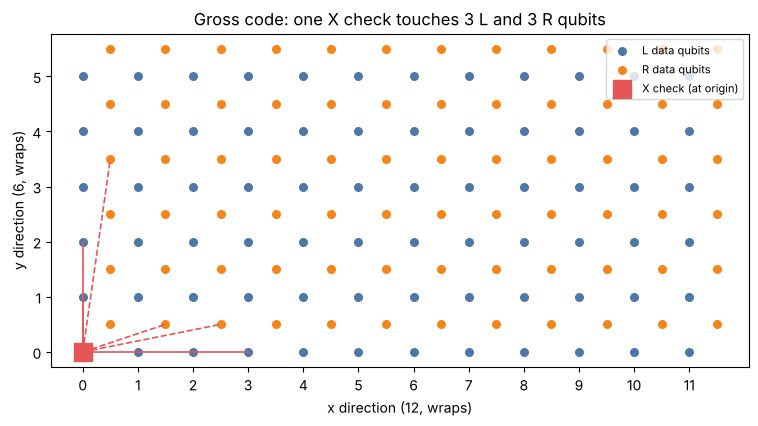

In [7]:
def monomials(P):
    # grid points (i, j) where the first row of polynomial matrix P has a 1
    return [(int(c // m), int(c % m)) for c in np.nonzero(P[0])[0]]
L_pts, R_pts = monomials(A), monomials(B)
print("X check at origin touches L qubits at", L_pts, "and R qubits at", R_pts)
fig, ax = plt.subplots(figsize=(9, 4.6))
gi, gj = np.meshgrid(range(l), range(m), indexing="ij")
ax.scatter(gi, gj, s=30, c="#4c78a8", label="L data qubits")
ax.scatter(gi + .5, gj + .5, s=30, c="#f58518", label="R data qubits")
ax.scatter([0], [0], s=160, marker="s", c="#e45756", label="X check (at origin)", zorder=3)
for (i, j) in L_pts:
    ax.plot([0, i], [0, j], c="#e45756", lw=1.2)
for (i, j) in R_pts:
    ax.plot([0, i + .5], [0, j + .5], c="#e45756", lw=1.2, ls="--")
ax.set_xticks(range(l)); ax.set_yticks(range(m)); ax.set_aspect("equal")
ax.set_xlabel("x direction (12, wraps)"); ax.set_ylabel("y direction (6, wraps)")
ax.set_title("Gross code: one X check touches 3 L and 3 R qubits")
ax.legend(loc="upper right", fontsize=8); plt.show()

## 7. Logical operators and distance

The distance d is the weight of the lightest logical operator. Bravyi et al. report d = 12
for this code (found by integer linear programming); computing it exactly is expensive, so here we look
at the logical operators stabilizer-qec gives and their weights.

In [8]:
LX, LZ = sq.BivariateBicycleCode("gross").logicals()
print("logical X weights:", LX.sum(1))
print("logical Z weights:", LZ.sum(1))
print("each logical X commutes with every Z check:", not (HZ @ LX.T % 2).any())
print("each logical Z commutes with every X check:", not (HX @ LZ.T % 2).any())
print("pairing X_i with Z_j anticommutes iff i = j:", np.array_equal(LX @ LZ.T % 2, np.eye(12, dtype=int)))

logical X weights: [12 14 14 16 12 12 12 36 36 12 36 36]
logical Z weights: [12 12 12 12 12 12 24 12 36 34 28 38]
each logical X commutes with every Z check: True
each logical Z commutes with every X check: True
pairing X_i with Z_j anticommutes iff i = j: True


## 8. Shift automorphisms

Shifting every qubit by x^a y^b (L qubits by the shift, R qubits by the same shift) maps every
check to another check, so the code maps to itself. The logical qubits get rearranged:
Tour de gross uses these shifts to bring any logical qubit into slots 1 or 7, the two it can measure directly.

In [9]:
def shift_perm(a, b):
    # permutation matrix acting on all 144 data qubits for the shift x^a y^b
    T = mpow(x, a) @ mpow(y, b) % 2
    return np.block([[T, np.zeros_like(T)], [np.zeros_like(T), T]])
P = shift_perm(1, 0)
# a code automorphism: the shifted checks are the same SET of checks (rows permuted)
same_rows = lambda H, H2: sorted(map(tuple, H)) == sorted(map(tuple, H2))
print("H_X maps to itself under x^1:", same_rows(HX, HX @ P.T % 2))
print("H_Z maps to itself under x^1:", same_rows(HZ, HZ @ P.T % 2))
auts = sq.BivariateBicycleCode("gross").automorphisms()
print(len(auts), "automorphisms in stabilizer-qec (72 shifts x with/without ZX duality)")

H_X maps to itself under x^1: True
H_Z maps to itself under x^1: True


144 automorphisms in stabilizer-qec (72 shifts x with/without ZX duality)


## 9. Cost compared with the surface code

To hold 12 logical qubits at distance 12:

In [10]:
surface_per_patch = 2 * 12**2 - 1          # rotated surface code: d^2 data + d^2 - 1 check qubits
print("12 rotated surface patches, d = 12:", 12 * surface_per_patch, "physical qubits")
print("one gross code block:              ", 144 + 144, "physical qubits (144 data + 144 check)")
print("ratio:", round(12 * surface_per_patch / 288, 1), "x fewer qubits")

12 rotated surface patches, d = 12: 3444 physical qubits
one gross code block:               288 physical qubits (144 data + 144 check)
ratio: 12.0 x fewer qubits


## 10. The family (Bravyi et al. Table 3)

In [11]:
for name in ["72", "90", "108", "gross", "288"]:
    c = sq.BivariateBicycleCode(name)
    print(f"{name:6s} n = {c.n:4d}  k = {c.k:3d}")

72     n =   72  k =  12
90     n =   90  k =   8
108    n =  108  k =   8
gross  n =  144  k =  12
288    n =  288  k =  12


## Summary

- The gross code is a CSS code defined by two polynomials on a 12 × 6 torus.
- It uses the same 144 data qubits as a toric code on that torus, but stores 12 logical qubits instead of 2, because of two long-range edges per check.
- Every check has weight 6, and every qubit is in 3 X and 3 Z checks.
- The same check matrices come out of our numpy code, stabilizer-qec and Deltakit.
- 288 physical qubits do the job of 3,444 in surface code patches, at the cost of long-range connections and harder logical gates (automorphisms + measurements).